In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df=pd.read_csv("/content/drive/MyDrive/All FACK_DATA/ecommerce_sales_data_analytics.csv")
print(df.head(10).to_string())

   order_id  order_date  customer_id product_category region  quantity  unit_price  discount payment_method  delivery_days  customer_rating  revenue
0     10001  2022-01-01         1102           Beauty  South         7      373.65      0.28         Wallet             10              4.7  1883.20
1     10002  2022-01-02         1435         Clothing  South         7       47.74      0.09           Card              6              3.9   304.10
2     10003  2022-01-03         1860           Beauty   East         3      311.28      0.31            COD              6              2.5   644.35
3     10004  2022-01-04         1270      Electronics   West         5      524.47      0.02         Wallet              6              1.6  2569.90
4     10005  2022-01-05         1106         Clothing   West         5      139.87      0.33         Wallet              4              4.9   468.56
5     10006  2022-01-06         1071      Electronics   West         2      264.44      0.20           Car

In [4]:
# Check number of rows and columns
print(df.shape)

# Check column names
print(df.columns)

# Check data types and non-null values
print(df.info())

# Statistical summary
print(df.describe())
print(df.describe(include="object"))

(5000, 12)
Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes

In [5]:
# Check total missing values
print(df.isnull().sum())
print(df.isnull().sum().sum())


order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64
0


In [6]:
# Check duplicate rows
print(df.duplicated().sum())
# Remove exact duplicate rows, if any
print(df.drop_duplicates(inplace=True))


0
None


In [7]:


#count total product per category
print(df['product_category'].value_counts())

#count total payments methods
print(df['payment_method'].value_counts())

#count total region
print(df['region'].value_counts())

#count order_id
print(df['order_id'].count())



product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64
payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64
region
West     1289
North    1276
East     1227
South    1208
Name: count, dtype: int64
5000


#Product Category Bar Plot

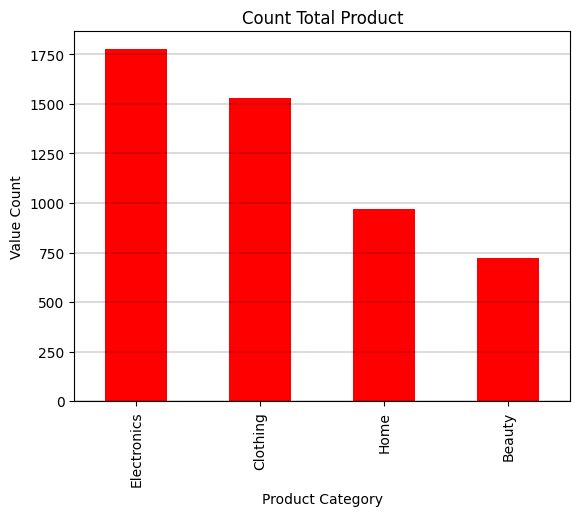

In [8]:
x=df['product_category'].value_counts()
x.plot(kind="bar",color="red")
plt.grid(axis="y",linewidth=0.2,color="k")
plt.xlabel("Product Category")
plt.ylabel("Value Count")
plt.title("Count Total Product")

plt.show()

In [10]:
#per category max quantity
result=df.groupby('product_category')["quantity"].max()
print(result)

#per catergory total quantity
ans=df.groupby('product_category')["quantity"].sum()
print(ans)

print(df['quantity'].sum())

product_category
Beauty         7
Clothing       7
Electronics    7
Home           7
Name: quantity, dtype: int64
product_category
Beauty         2995
Clothing       6171
Electronics    7109
Home           3949
Name: quantity, dtype: int64
20224


In [11]:
#add new column total price
df["total_price"]=df['quantity']* df['unit_price']
print(df.head(10).to_string())

#add new column total discount
df["discount_per_item"]=df['unit_price']*df["discount"]
df["total_discount"]=df["discount"]*df["total_price"]
print(df.head(10).to_string())

   order_id  order_date  customer_id product_category region  quantity  unit_price  discount payment_method  delivery_days  customer_rating  revenue  total_price
0     10001  2022-01-01         1102           Beauty  South         7      373.65      0.28         Wallet             10              4.7  1883.20      2615.55
1     10002  2022-01-02         1435         Clothing  South         7       47.74      0.09           Card              6              3.9   304.10       334.18
2     10003  2022-01-03         1860           Beauty   East         3      311.28      0.31            COD              6              2.5   644.35       933.84
3     10004  2022-01-04         1270      Electronics   West         5      524.47      0.02         Wallet              6              1.6  2569.90      2622.35
4     10005  2022-01-05         1106         Clothing   West         5      139.87      0.33         Wallet              4              4.9   468.56       699.35
5     10006  2022-01-06     

In [12]:
#total price
result=df['total_price'].sum()
print("Total Price: ",result)


#total revenue
res=df['revenue'].sum()
print("Total Revenue:",res)

Total Price:  6240021.96
Total Revenue: 5109775.74


In [13]:
#total region count per each category

print("total region count for Beauty category:")
print(df[df["product_category"]=="Beauty"]["region"].value_counts())

print("total region count for Home category:")
print(df[df["product_category"]=="Home"]["region"].value_counts())

print("\ntotal region count for Clothing  category: ")
print(df[df["product_category"]=="Clothing"]["region"].value_counts())

print("\n total region count per electronics category:")
print(df[df["product_category"]=="Electronics"]["region"].value_counts())


total region count for Beauty category:
region
North    194
West     192
South    172
East     165
Name: count, dtype: int64
total region count for Home category:
region
West     262
East     249
North    242
South    216
Name: count, dtype: int64

total region count for Clothing  category: 
region
East     395
West     393
North    378
South    365
Name: count, dtype: int64

 total region count per electronics category:
region
North    462
South    455
West     442
East     418
Name: count, dtype: int64


In [14]:
#per category total price
elect=df[df["product_category"]=="Electronics"]["total_price"].sum()
print("\n Electronics total price:",elect)

cloth=df[df['product_category']=="Clothing"]["total_price"].sum()
print("\n Clothing total price:",cloth)

home=df[df['product_category']=="Home"]["total_price"].sum()
print("\n Home total price:",home)

beauty=df[df['product_category']=="Beauty"]["total_price"].sum()
print("\n Beauty total price:",beauty)


 Electronics total price: 2223312.5700000003

 Clothing total price: 1887131.5

 Home total price: 1196217.97

 Beauty total price: 933359.9199999999


In [15]:
#per category total revenue
elect=df[df["product_category"]=="Electronics"]["revenue"].sum()
print("\n Electronics total revenue:",elect)

cloth=df[df['product_category']=="Clothing"]["revenue"].sum()
print("\n Clothing total revenue:",cloth)

home=df[df['product_category']=="Home"]["revenue"].sum()
print("\n Home total revenue:",home)

beauty=df[df['product_category']=="Beauty"]["revenue"].sum()
print("\n Beauty total revenue:",beauty)


 Electronics total revenue: 1829899.22

 Clothing total revenue: 1531931.72

 Home total revenue: 982083.92

 Beauty total revenue: 765860.88


In [16]:
# maximum delivery_days
max=df["delivery_days"].max()
print("Maximum delivery days: ",max)
# minimum delivery_days
min=df["delivery_days"].min()
print("Minimum delivery days: ",min)

Maximum delivery days:  11
Minimum delivery days:  1


In [17]:
#per Category maximum delivery_days
max2=df.groupby("product_category")["delivery_days"].max()
print("per Category maximum delivery_days:",max2)

#per Category minimum delivery_days
min2=df.groupby("product_category")["delivery_days"].min()
print("per Category minimum delivery_days:",min2)


per Category maximum delivery_days: product_category
Beauty         11
Clothing       11
Electronics    11
Home           11
Name: delivery_days, dtype: int64
per Category minimum delivery_days: product_category
Beauty         1
Clothing       1
Electronics    1
Home           1
Name: delivery_days, dtype: int64


#  1. Product Category Analysis


In [18]:

# Which product category has the highest total revenue?
rev=df.groupby("product_category")["revenue"].sum().idxmax()
print(rev)

# Which product category has the lowest total revenue?
rev1=df.groupby("product_category")["revenue"].sum().idxmin()
print(rev1)



Electronics
Beauty


In [19]:
# Which category has the highest total quantity sold?
quan=df.groupby("product_category")["quantity"].sum().idxmax()
print(quan)

# Which category has the lowest total quantity sold?
low=df.groupby("product_category")["quantity"].sum().idxmin()
print(low)
# Find the average quantity per category.
cat=df.groupby("product_category")["quantity"].mean()
print("average quantity per category:\n",cat)

Electronics
Beauty
average quantity per category:
 product_category
Beauty         4.142462
Clothing       4.030699
Electronics    4.000563
Home           4.075335
Name: quantity, dtype: float64


In [20]:
# Find the average,maximum and minimum unit price per category.
uni=df.groupby("product_category")["unit_price"].agg(["mean","max","min"])
print(uni)



                        mean     max    min
product_category                           
Beauty            304.712891  598.08  15.50
Clothing          304.010901  598.76  15.15
Electronics       314.902656  599.96  15.78
Home              306.257730  599.68  17.35


In [21]:
# Find the average discount per category.
dis=df.groupby("product_category")["discount"].mean()
print(dis)
# Find the maximum discount per category.
print("\n")
dis1=df.groupby("product_category")["discount"].max()
print(dis1)

product_category
Beauty         0.181425
Clothing       0.184259
Electronics    0.176652
Home           0.178266
Name: discount, dtype: float64


product_category
Beauty         0.35
Clothing       0.35
Electronics    0.35
Home           0.35
Name: discount, dtype: float64


In [22]:
# Find the average customer rating per category.
rat=df.groupby("product_category")["customer_rating"].mean()
print(rat)
# Which category has the highest average customer rating?
rat1=df.groupby("product_category")["customer_rating"].mean()
print(rat1.idxmax())

product_category
Beauty         3.008990
Clothing       3.005095
Electronics    2.951097
Home           2.940660
Name: customer_rating, dtype: float64
Beauty


# 2. Region Analysis

In [23]:

#total quantity
print("Total Quantity:",df["quantity"].sum())
print("total price:",df["total_price"].sum())

# Find the total quantity,revenue and total price  sold per region.
reg=df.groupby("region")[["quantity","total_price","revenue"]].sum()
print(reg,"\n")




Total Quantity: 20224
total price: 6240021.96
        quantity  total_price     revenue
region                                   
East        4916   1515170.57  1236044.23
North       5164   1566659.99  1281508.45
South       4884   1517429.39  1246640.90
West        5260   1640762.01  1345582.16 



Per region average for revnue , unit price and discount we give

In [24]:
# Find the average revenue,unit price, discount,delivery days and customeer rating  per region.
average=df.groupby("region")[["revenue","unit_price","discount","delivery_days","customer_rating"]].mean()
print(average)


            revenue  unit_price  discount  delivery_days  customer_rating
region                                                                   
East    1007.371011  307.767604  0.183032       6.104319         2.973187
North   1004.316967  305.104890  0.180016       6.118339         2.993182
South   1031.987500  310.252947  0.175513       6.173013         2.967798
West    1043.896168  310.600171  0.181241       6.082234         2.961521


In [25]:
# Find the maximum unit price per region.
max=df.groupby("region")["unit_price"].max()
print(max,"\n")
# Find the minimum unit price per region.
min=df.groupby("region")["unit_price"].min()
print(min)

region
East     599.89
North    599.21
South    599.32
West     599.96
Name: unit_price, dtype: float64 

region
East     15.67
North    15.19
South    15.15
West     15.18
Name: unit_price, dtype: float64


In [26]:
# Which region has the highest revenue?
reve=df.groupby("region")["revenue"].sum().idxmax()
print(reve,"\n")
# Which region has the highest quantity sold?
qun=df.groupby("region")["quantity"].sum().idxmax()
print(qun,"\n")
# Which region has the best average customer rating?
rat=df.groupby("region")["customer_rating"].mean().idxmax()
print(rat)


West 

West 

North


# 3. Category + Region Analysis

Find the **total** for revenue,quantity and total price in each category and each region

In [27]:
# Find total revenue ,quantity and total price for each category in each region.
rev=df.groupby(["region","product_category"])[["revenue","quantity","total_price"]].sum()
print(rev)




                           revenue  quantity  total_price
region product_category                                  
East   Beauty            174909.11       649    214054.13
       Clothing          402582.60      1618    495117.31
       Electronics       411803.35      1648    505223.78
       Home              246749.17      1001    300775.35
North  Beauty            186213.32       787    227175.73
       Clothing          364659.43      1503    450684.11
       Electronics       472450.93      1860    574351.67
       Home              258184.77      1014    314448.48
South  Beauty            191073.98       745    234741.04
       Clothing          348363.14      1428    425491.22
       Electronics       487055.68      1851    590117.88
       Home              220148.10       860    267079.25
West   Beauty            213664.47       814    257389.02
       Clothing          416326.55      1622    515838.86
       Electronics       458589.26      1750    553619.24
       Home   

Find the **average** for revenue,discount,delivery days and customer rating in each category and each region

In [28]:
# Find average revenue,discount,delivery days and customer rating  for each category in each region.
rev=df.groupby(["region","product_category"])[["revenue","discount","delivery_days","customer_rating"]].mean()
print(rev)



                             revenue  discount  delivery_days  customer_rating
region product_category                                                       
East   Beauty            1060.055212  0.182788       5.945455         2.952727
       Clothing          1019.196456  0.184962       6.015190         3.066582
       Electronics        985.175478  0.180550       6.138756         2.906938
       Home               990.960522  0.184297       6.293173         2.949799
North  Beauty             959.862474  0.179124       6.319588         3.172680
       Clothing           964.707487  0.183968       6.248677         2.947354
       Electronics       1022.621061  0.176277       5.941558         2.938528
       Home              1066.879215  0.181694       6.090909         3.025207
South  Beauty            1110.895233  0.184070       6.273256         2.965698
       Clothing           954.419562  0.175260       6.065753         2.966575
       Electronics       1070.452044  0.175560      

find the which category + region has highest revenue and quantity

In [29]:
# Find which category + region combination has the highest revenue and quantity.
rev=df.groupby(["region","product_category"])[["revenue","quantity"]].sum().idxmax()
print(rev)
print("\n")




revenue     (South, Electronics)
quantity    (North, Electronics)
dtype: object




#  4. Payment Method Analysis



In [30]:
# Count orders for each payment method.
pay=df["payment_method"].value_counts()
print(pay)
print("\n")
# Find total revenue and quantity  per payment method.
rev=df.groupby("payment_method")[["revenue","quantity"]].sum()
print(rev)
print("\n")

# Find average order value ,discount,customer rating and delivery days  per payment method.
ave=df.groupby("payment_method")[["total_price","discount","customer_rating","delivery_days"]].mean()
print(ave)
print("\n")
# Which payment method generates the highest revenue?
rev=df.groupby("payment_method")["revenue"].sum().idxmax()
print(rev)
# Which payment method has the highest number of orders?
order=df.groupby("payment_method")["order_id"].sum().idxmax()
print(order)

payment_method
Card      2270
COD       1774
Wallet     956
Name: count, dtype: int64


                   revenue  quantity
payment_method                      
COD             1788408.44      7047
Card            2366248.20      9333
Wallet           955119.10      3844


                total_price  discount  customer_rating  delivery_days
payment_method                                                       
COD             1230.574402  0.181635         2.941939       6.158963
Card            1275.823758  0.181383         3.017357       6.087225
Wallet          1214.291883  0.173598         2.930439       6.119247


Card
Card


# 5. Customer Analysis

In [31]:
# Count total orders per customer.
order=df.groupby("customer_id")["order_id"].count()
print(order.head(20))

customer_id
1000     9
1001     6
1002     4
1003     2
1004     5
1005     1
1006     7
1007     7
1008     3
1009     6
1010     4
1011    10
1012     5
1013     4
1014     5
1015     5
1016     8
1017     2
1018     7
1019     7
Name: order_id, dtype: int64


In [32]:
# Find total quantity ,revenue and total price purchased by each customer.
qua=df.groupby("customer_id")[["quantity","revenue","total_price"]].sum()
print(qua)

             quantity  revenue  total_price
customer_id                                
1000               27  6905.58      7982.39
1001               18  3959.74      5205.53
1002               15  1579.67      1963.26
1003                9  2304.44      2843.79
1004               16  6073.85      6796.28
...               ...      ...          ...
1995               20  4082.06      4644.27
1996               32  7053.98      8665.70
1997               31  6466.30      8622.51
1998               31  7213.69      9357.33
1999                5   465.53       705.35

[989 rows x 3 columns]


In [33]:
# Find average customer rating per customer.
rat=df.groupby("customer_id")["customer_rating"].mean()
print(rat)

customer_id
1000    2.633333
1001    2.666667
1002    3.800000
1003    3.000000
1004    2.320000
          ...   
1995    2.650000
1996    2.328571
1997    3.483333
1998    3.360000
1999    4.200000
Name: customer_rating, Length: 989, dtype: float64


In [34]:
# Find the customer with the highest total revenue and quantity.
rev=df.groupby("customer_id")[["revenue","quantity"]].sum().idxmax()
print(rev)



revenue     1663
quantity    1663
dtype: int64


In [35]:
# Find customers who placed more than 5 orders.
order_count=df.groupby("customer_id")["order_id"].count()
oder=order_count[order_count > 5]
print(oder)
print("\n")

# Find the top 10 customers by revenue.
rev=df.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)
print(rev.head(10))

print("\n")
# Find the top 10 customers by quantity.
qua=df.groupby("customer_id")["quantity"].sum().sort_values(ascending=False)
print(qua.head(10))

customer_id
1000    9
1001    6
1006    7
1007    7
1009    6
       ..
1989    8
1992    6
1993    6
1996    7
1997    6
Name: order_id, Length: 399, dtype: int64


customer_id
1663    17680.69
1955    16265.15
1675    15036.46
1276    15023.71
1647    14894.97
1804    14330.98
1193    14151.65
1836    14110.78
1957    13956.95
1735    13146.25
Name: revenue, dtype: float64


customer_id
1663    63
1957    57
1675    55
1935    51
1276    50
1038    48
1496    48
1775    48
1267    48
1117    47
Name: quantity, dtype: int64


#  6. Order Analysis

In [36]:
# Find the average order value.
print(df["total_price"].mean())
# Find the maximum order value.
print(df["total_price"].max())
# Find the minimum order value.
print(df["total_price"].min())



1248.004392
4196.5
15.15


In [37]:
# Find the order with the highest revenue,quantity,discount and delivery days .
rev=df.groupby("order_id")[["revenue","quantity","discount","delivery_days"]].max().idxmax()
print(rev)

#find using loc
rev1=df.loc[df['revenue'].idxmax()]
print(rev1)


revenue          10810
quantity         10001
discount         10095
delivery_days    10012
dtype: int64
order_id                   10810
order_date            2024-03-20
customer_id                 1890
product_category     Electronics
region                     South
quantity                       7
unit_price                594.42
discount                    0.01
payment_method              Card
delivery_days                  4
customer_rating              4.9
revenue                  4119.33
total_price              4160.94
discount_per_item         5.9442
total_discount           41.6094
Name: 809, dtype: object


In [38]:
# Find orders where quantity > average quantity.
qua=df.loc[df["quantity"] > df["quantity"].mean()]
print(qua.head(5).to_string())
# Find orders where revenue > average revenue.
rev=df.loc[df["revenue"] > df["revenue"].mean()]
print(rev.head(5).to_string())
# Find orders where discount > average discount.
dis=df.loc[df["total_discount"] > df["total_discount"].mean()]
print(dis.head(5).to_string())




   order_id  order_date  customer_id product_category region  quantity  unit_price  discount payment_method  delivery_days  customer_rating  revenue  total_price  discount_per_item  total_discount
0     10001  2022-01-01         1102           Beauty  South         7      373.65      0.28         Wallet             10              4.7  1883.20      2615.55           104.6220        732.3540
1     10002  2022-01-02         1435         Clothing  South         7       47.74      0.09           Card              6              3.9   304.10       334.18             4.2966         30.0762
3     10004  2022-01-04         1270      Electronics   West         5      524.47      0.02         Wallet              6              1.6  2569.90      2622.35            10.4894         52.4470
4     10005  2022-01-05         1106         Clothing   West         5      139.87      0.33         Wallet              4              4.9   468.56       699.35            46.1571        230.7855
6     10007  20

# 7. Date / Time Analysis




In [39]:
df["order_date"]=pd.to_datetime(df["order_date"])
df["Day"]=df["order_date"].dt.day
df["Month"]=df["order_date"].dt.month
df["Year"]=df["order_date"].dt.year
print(df.head().to_string())
print(df.tail().to_string())



   order_id order_date  customer_id product_category region  quantity  unit_price  discount payment_method  delivery_days  customer_rating  revenue  total_price  discount_per_item  total_discount  Day  Month  Year
0     10001 2022-01-01         1102           Beauty  South         7      373.65      0.28         Wallet             10              4.7  1883.20      2615.55           104.6220        732.3540    1      1  2022
1     10002 2022-01-02         1435         Clothing  South         7       47.74      0.09           Card              6              3.9   304.10       334.18             4.2966         30.0762    2      1  2022
2     10003 2022-01-03         1860           Beauty   East         3      311.28      0.31            COD              6              2.5   644.35       933.84            96.4968        289.4904    3      1  2022
3     10004 2022-01-04         1270      Electronics   West         5      524.47      0.02         Wallet              6              1.6  2569

In [40]:
# Total revenue and quantity per year

total=df.groupby("Year")[["revenue","quantity"]].sum()
print(total)




         revenue  quantity
Year                      
2022  1509318.00      5878
2023  1356051.89      5483
2024  1126638.56      4457
2025  1117767.29      4406


In [41]:
# 4. Average, maximum and minimum revenue per year
reve=df.groupby("Year")["revenue"].agg(["mean","max","min"])
print(reve)



             mean      max    min
Year                             
2022  1033.779452  4005.93  13.01
2023  1006.720037  4083.17  11.21
2024  1026.082477  4119.33  13.47
2025  1020.792046  3807.92  13.20


In [42]:
#  Total orders per month
ord=df.groupby("Month")["order_id"].count()
print(ord)


Month
1     434
2     395
3     434
4     420
5     434
6     420
7     434
8     434
9     399
10    403
11    390
12    403
Name: order_id, dtype: int64


In [43]:
#  Average,max and total revenue per month
rev=df.groupby("Month")["revenue"].agg(["mean","max","sum"])
print(rev)

              mean      max        sum
Month                                 
1       982.430691  4055.29  426374.92
2      1047.823392  3928.63  413890.24
3       979.379078  4119.33  425050.52
4       949.321810  3678.38  398715.16
5      1105.466705  4083.17  479772.55
6      1054.622810  4005.93  442941.58
7      1015.139908  3713.89  440570.72
8      1061.923456  3532.46  460874.78
9      1008.441378  3775.88  402368.11
10     1012.092109  3868.11  407873.12
11     1052.968923  3893.11  410657.88
12      994.258462  3568.81  400686.16


In [44]:
# Total revenue per year and month
rev=df.groupby(["Year","Month"])["revenue"].agg(["sum","max"])
print(rev)


                  sum      max
Year Month                    
2022 1      117745.95  2879.37
     2      114958.55  3640.56
     3      115236.53  3467.67
     4      112101.05  3678.38
     5      139828.11  3473.99
     6      131436.67  4005.93
     7      136750.36  3600.65
     8      129739.16  3532.46
     9      120909.08  3445.18
     10     121529.60  3248.28
     11     131507.14  3893.11
     12     137575.80  3568.81
2023 1      134278.55  3630.66
     2      122065.46  3137.33
     3      129018.49  3898.48
     4      116720.32  3538.20
     5      133719.15  4083.17
     6      115459.92  3264.05
     7      109735.83  3095.55
     8      129486.52  3341.37
     9      101371.15  3775.88
     10      96037.84  3868.11
     11      91848.07  3168.57
     12      76310.59  3474.21
2024 1       87533.49  4055.29
     2       95959.28  3928.63
     3       84354.75  4119.33
     4       90685.60  3443.91
     5      105024.43  3757.89
     6       89543.54  3623.47
     7  

# 8. Discount Analysis

In [45]:
# Find the total discount.
print("Total discounts:",df["total_discount"].sum())
# Find the average,maximum and minimum discount.
dis=df["total_discount"].agg(["mean","max","min"])
print(dis)



Total discounts: 1130246.0760000001
mean     226.049215
max     1424.049200
min        0.000000
Name: total_discount, dtype: float64


In [46]:
# Find total discount and average per category.
category=df.groupby("product_category")["total_discount"]
print("total:\n",category.sum())
print("average\n:",category.mean())



total:
 product_category
Beauty         167498.9031
Clothing       355199.8578
Electronics    393413.3139
Home           214134.0012
Name: total_discount, dtype: float64
average
: product_category
Beauty         231.672065
Clothing       232.005132
Electronics    221.391848
Home           220.984521
Name: total_discount, dtype: float64


In [47]:
# Find total discount per region.

region=df.groupby("region")["total_discount"].sum()
print(region)


region
East     279126.3174
North    285151.4129
South    270788.5798
West     295179.7659
Name: total_discount, dtype: float64


In [48]:
# Find average discount per payment method.
pay=df.groupby("payment_method")["total_discount"].mean()
print(pay)



payment_method
COD       222.452440
Card      233.423581
Wallet    215.213303
Name: total_discount, dtype: float64


In [49]:
# Find the order with the highest discount.
order=df.groupby("order_id")["total_discount"].max()
print(order.max())
print(order.idxmax())



1424.0492000000002
14236


In [50]:
# Find categories where the average discount is greater than the overall average discount
all=df["total_discount"].mean()
print(all)
category=df.groupby("product_category")["total_discount"].mean()
print(category)
ans=category[category > all]
print(ans)



226.04921520000002
product_category
Beauty         231.672065
Clothing       232.005132
Electronics    221.391848
Home           220.984521
Name: total_discount, dtype: float64
product_category
Beauty      231.672065
Clothing    232.005132
Name: total_discount, dtype: float64


# 9. Customer Rating Analysis

In [51]:
# Find the average, maximum and minimum customer rating overall.

rating=df["customer_rating"].agg(["mean","max","min"])
rating

,customer_rating
mean,2.97398
max,5.00000
min,1.00000


In [52]:
# Find average rating per category.
print(df.groupby("product_category")["customer_rating"].mean())
# Find average rating per region.
print(df.groupby("region")["customer_rating"].mean())
# Find average rating per payment method.
print(df.groupby("payment_method")["customer_rating"].mean())




product_category
Beauty         3.008990
Clothing       3.005095
Electronics    2.951097
Home           2.940660
Name: customer_rating, dtype: float64
region
East     2.973187
North    2.993182
South    2.967798
West     2.961521
Name: customer_rating, dtype: float64
payment_method
COD       2.941939
Card      3.017357
Wallet    2.930439
Name: customer_rating, dtype: float64


In [53]:
# Find categories with average rating > 3.
rat=df.groupby("product_category")["customer_rating"].mean()
rating=rat[rat > 3]
print(rating)

# Find orders where customer_rating >= 4.5.
rat=df[df["customer_rating"] >= 4.5]
print(rat.head(10).to_string())



product_category
Beauty      3.008990
Clothing    3.005095
Name: customer_rating, dtype: float64
    order_id order_date  customer_id product_category region  quantity  unit_price  discount payment_method  delivery_days  customer_rating  revenue  total_price  discount_per_item  total_discount  Day  Month  Year
0      10001 2022-01-01         1102           Beauty  South         7      373.65      0.28         Wallet             10              4.7  1883.20      2615.55           104.6220        732.3540    1      1  2022
4      10005 2022-01-05         1106         Clothing   West         5      139.87      0.33         Wallet              4              4.9   468.56       699.35            46.1571        230.7855    5      1  2022
9      10010 2022-01-10         1121         Clothing   West         4      272.71      0.06           Card             10              4.5  1025.39      1090.84            16.3626         65.4504   10      1  2022
20     10021 2022-01-21         1661       

In [54]:
# Find the category with the highest average rating.
rat=df.groupby("product_category")["customer_rating"].mean()
print(rat)
print(rat.idxmax())
print(rat.max())


product_category
Beauty         3.008990
Clothing       3.005095
Electronics    2.951097
Home           2.940660
Name: customer_rating, dtype: float64
Beauty
3.008990318118949


In [55]:
# Find the region with the lowest average rating.
rat=df.groupby("region")["customer_rating"].mean()
print(rat)
print(rat.idxmin())
print(rat.min())

region
East     2.973187
North    2.993182
South    2.967798
West     2.961521
Name: customer_rating, dtype: float64
West
2.961520558572537


# 10. Combined / Advanced Analysis


In [56]:
# Find the top 5 categories by revenue.
rev=df.groupby("product_category")["revenue"].sum().sort_values(ascending=False)
print(rev)



product_category
Electronics    1829899.22
Clothing       1531931.72
Home            982083.92
Beauty          765860.88
Name: revenue, dtype: float64


In [57]:
# Find the top 5 regions by revenue.
region=df.groupby("region")["revenue"].sum().sort_values(ascending=False)
print(region)


region
West     1345582.16
North    1281508.45
South    1246640.90
East     1236044.23
Name: revenue, dtype: float64


In [58]:
# Find the top 10 orders by revenue.
order=df.groupby("order_id")["revenue"].sum().sort_values(ascending=False)
print(order.head(10))



order_id
10810    4119.33
14884    4083.17
12215    4055.29
13102    4005.93
13687    3928.63
10158    3917.54
13350    3898.48
10322    3893.11
10662    3868.11
14306    3807.92
Name: revenue, dtype: float64


In [59]:
# Find the top 10 customers by revenue.
customer=df.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)
print(customer.head(10))

customer_id
1663    17680.69
1955    16265.15
1675    15036.46
1276    15023.71
1647    14894.97
1804    14330.98
1193    14151.65
1836    14110.78
1957    13956.95
1735    13146.25
Name: revenue, dtype: float64


In [60]:
# Find the top 10 customers by total quantity.
customer=df.groupby("customer_id")["quantity"].sum().sort_values(ascending=False)
print(customer.head(10))

customer_id
1663    63
1957    57
1675    55
1935    51
1276    50
1038    48
1496    48
1775    48
1267    48
1117    47
Name: quantity, dtype: int64


In [61]:
# Find the category with highest revenue but lowest delivery time.
category=df.groupby("product_category").agg(revenue=("revenue","sum"),
                                            delivery_days=("delivery_days","mean"))
print(category["revenue"].idxmax())
print(category["delivery_days"].idxmin())

Electronics
Electronics


In [62]:
# Find the region with highest revenue and highest customer rating.
region=df.groupby("region").agg(revenue=("revenue","sum"),
                                customer_rating=("customer_rating","mean"))
print(region["revenue"].idxmax())
print(region["customer_rating"].idxmax())


West
North


In [63]:
# Find the payment method with highest revenue and lowest average discount.
pay=df.groupby("payment_method").agg(revenue=("revenue","sum"),
                                     total_discount=("total_discount","mean"))

print(pay["revenue"].idxmax())
print(pay["total_discount"].idxmin())


Card
Wallet


                     revenue  total_price
product_category                         
Beauty             765860.88    933359.92
Clothing          1531931.72   1887131.50
Electronics       1829899.22   2223312.57
Home               982083.92   1196217.97


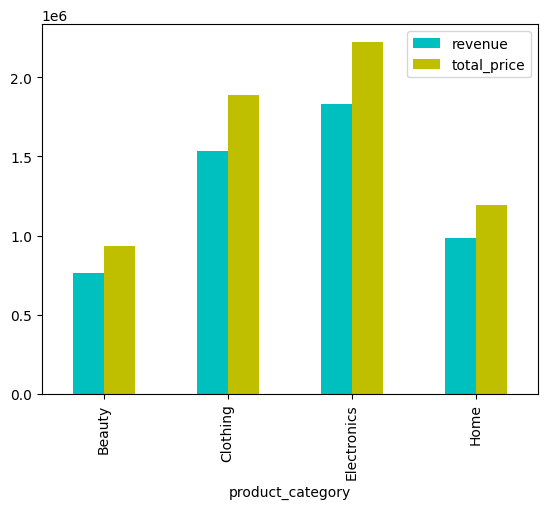

In [64]:
# Compare revenue vs total price for each category.
category=df.groupby("product_category").agg(revenue=("revenue","sum"),
                                            total_price=("total_price","sum"))
print(category)
category.plot(kind="bar",color=["c","y"])
plt.show()

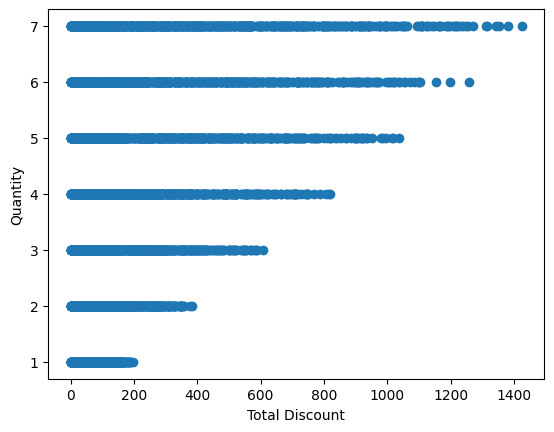

In [65]:
# Find whether higher discounts result in higher quantity sold.
x=df[["total_discount","quantity"]].corr()
x
plt.scatter(df["total_discount"], df["quantity"])
plt.xlabel("Total Discount")
plt.ylabel("Quantity")
plt.show()

In [66]:
# Find whether delivery days affect customer rating.
x=df[["delivery_days","customer_rating"]].corr()
print(x)


                 delivery_days  customer_rating
delivery_days         1.000000        -0.017625
customer_rating      -0.017625         1.000000


In [67]:
# Find whether unit price affects quantity sold.
x=df[["unit_price","quantity"]].corr()
print(x)

            unit_price  quantity
unit_price    1.000000  0.001498
quantity      0.001498  1.000000


In [68]:
# Find the correlation between numerical columns.

x=df[["quantity","unit_price","total_discount","delivery_days","customer_rating","revenue"]].corr()
x

,quantity,unit_price,total_discount,delivery_days,customer_rating,revenue
quantity,1.000000,0.001498,0.467867,-0.008748,0.019168,0.623564
unit_price,0.001498,1.000000,0.519300,0.015623,0.005025,0.678032
total_discount,0.467867,0.519300,1.000000,0.001267,0.013241,0.600011
delivery_days,-0.008748,0.015623,0.001267,1.000000,-0.017625,0.005444
customer_rating,0.019168,0.005025,0.013241,-0.017625,1.000000,0.012446
revenue,0.623564,0.678032,0.600011,0.005444,0.012446,1.000000


region
East      (East, Electronics)
North    (North, Electronics)
South    (South, Electronics)
West      (West, Electronics)
Name: revenue, dtype: object


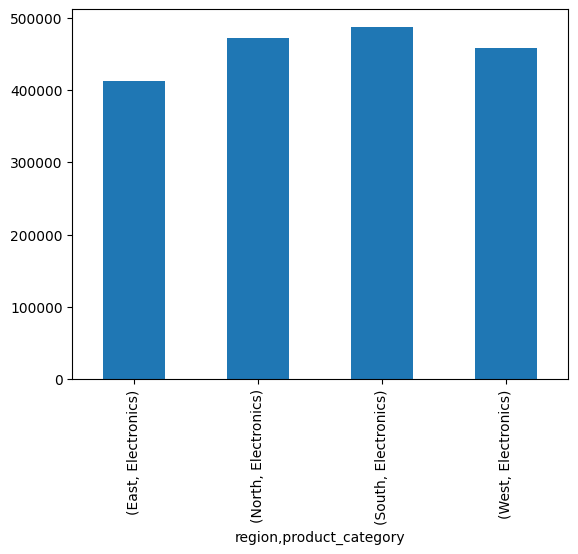

In [69]:
# Find the highest-revenue category in each region.
x=df.groupby(["region","product_category"])["revenue"].sum()
high=x.groupby(level="region").idxmax()
print(high)
high_rev=x.loc[high]
high_rev.plot(kind="bar")
plt.show()


product_category
Beauty               (Beauty, West)
Clothing           (Clothing, West)
Electronics    (Electronics, South)
Home                  (Home, North)
Name: revenue, dtype: object


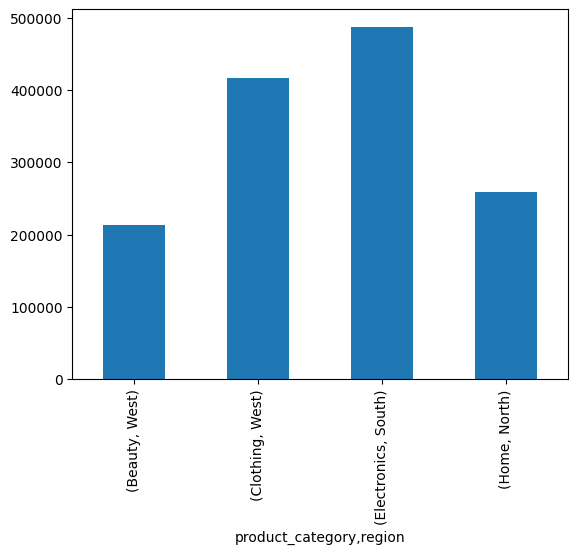

In [70]:
# Find the highest-revenue region for each category.
x=df.groupby(["product_category","region"])["revenue"].sum()
high=x.groupby(level="product_category").idxmax()
print(high)
high_rev=x.loc[high]
high_rev.plot(kind="bar")
plt.show()


                 delivery_days  customer_rating
delivery_days         1.000000        -0.017625
customer_rating      -0.017625         1.000000


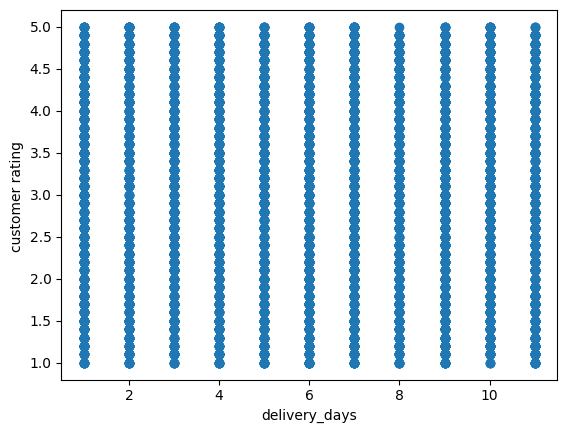

In [71]:

x=df[["delivery_days","customer_rating"]].corr()
print(x)
plt.scatter(df["delivery_days"],df["customer_rating"])
plt.xlabel("delivery_days")
plt.ylabel("customer rating ")
plt.show()

Boxplot

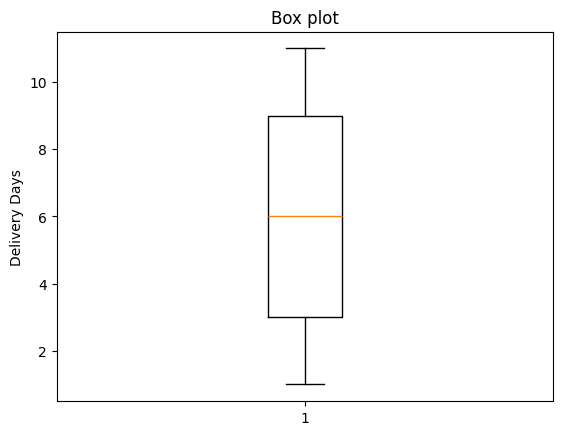

In [72]:
plt.boxplot(df["delivery_days"])
plt.ylabel("Delivery Days")
plt.title("Box plot")
plt.show()

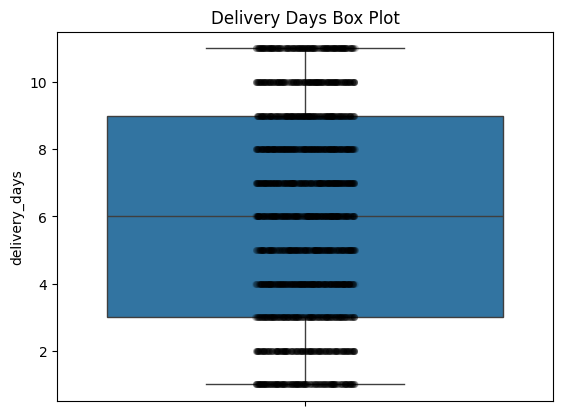

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(y=df["delivery_days"])
sns.stripplot(y=df["delivery_days"],color="black",alpha=0.1)

plt.title("Delivery Days Box Plot")
plt.show()

#scatterplot

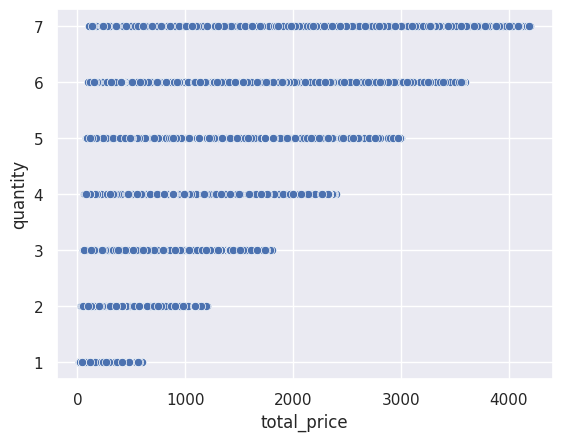

In [74]:
sns.set_theme()
sns.scatterplot(x=df["total_price"],y=df["quantity"])
plt.show()

#lineplot

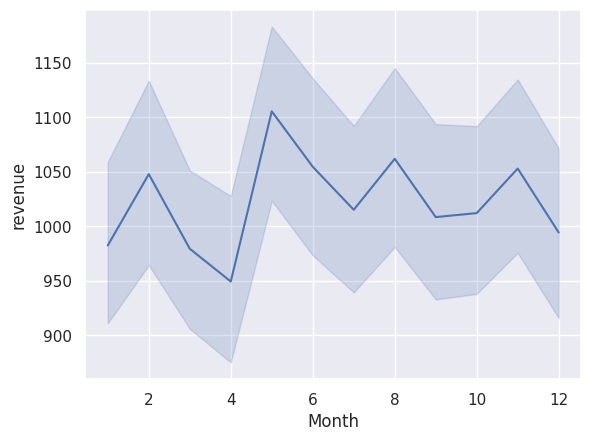

In [75]:
sns.lineplot(x=df["Month"],y=df["revenue"])
plt.show()

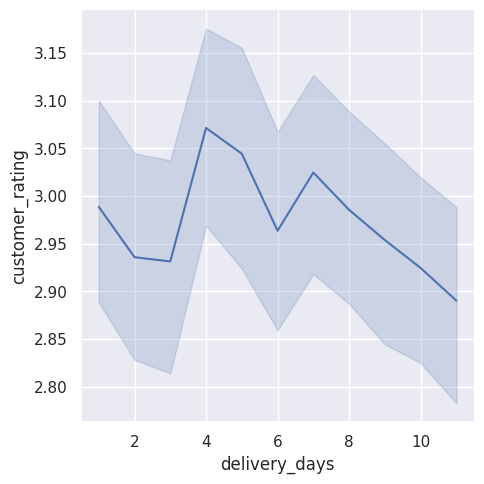

In [76]:
sns.relplot(
    data=df,
    x="delivery_days",
    y="customer_rating",
    kind="line"
)

plt.show()

#Boxplot

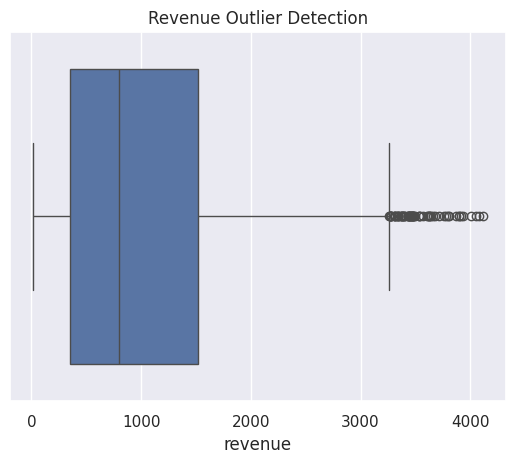

In [77]:
sns.boxplot(x=df["revenue"])

plt.title("Revenue Outlier Detection")
plt.show()

#4.relplot

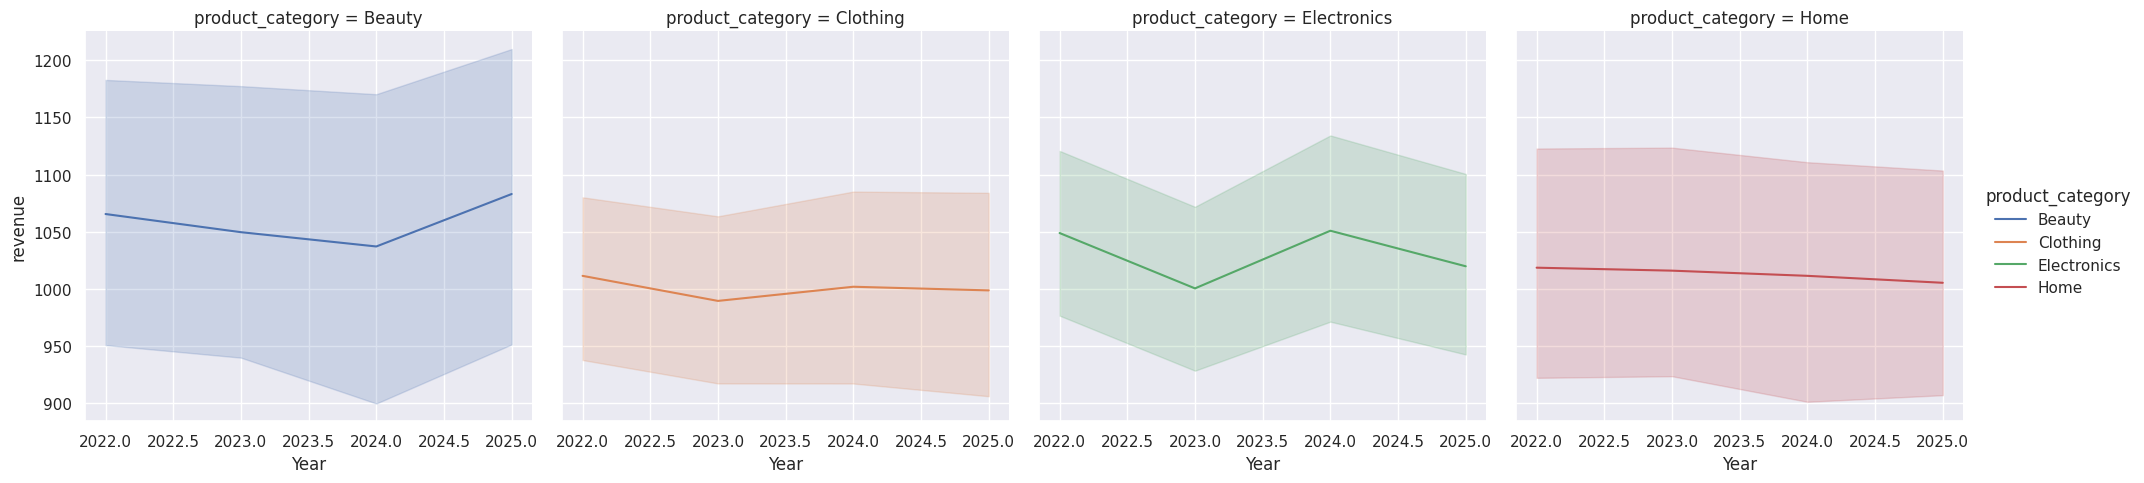

In [78]:
#relplot give you extra features for creating separate graphs by groups
sns.relplot(
    data=df,
    x="Year",
    y="revenue",
    col="product_category",
    hue="product_category",
    kind="line"
)

plt.show()

# Business Insights

1. Overall Sales Performance
*   The dataset contains 5,000 orders and 20,224 units sold. Total revenue was 5,109,775.74 from 989 customers.

2. Best-Performing Category
*  Electronics was the best-selling category. It generated the highest revenue of 1,829,899.22 and sold 7,109 units. Beauty had the lowest revenue.

3. Regional Sales Performance

* West was the best-performing region, with revenue of 1,345,582.16 and 5,260 units sold. East had the lowest revenue.

4. Payment Method Analysis

* Card was the most-used payment method, with 2,270 orders and revenue of 2,366,248.20. Wallet was the least-used payment method.

5. Customer Satisfaction
*   The average customer rating was 2.97 out of 5. Beauty and Clothing had the highest ratings of 3.01, while Home had the lowest rating of 2.94.


6. Delivery Performance
*  The average delivery time was 6.12 days. South had the highest average delivery time at 6.17 days, while West had the lowest at 6.08 days. Delivery time had almost no relationship with customer ratings.



7. Category Performance by Region
*   Electronics generated the highest revenue in all four regions. South had the highest Electronics revenue of 487,055.68.


8. Yearly Sales Performance
*   2022 had the highest revenue of 1,509,318.00. Revenue decreased every year and reached 1,117,767.29 in 2025.


# Business Recommendations
1. Increase Sales: Use better marketing and offers to attract more customers.
2. Focus on Electronics: Keep enough stock of Electronics because it generates the highest revenue.
3. Improve East Region Sales: Introduce promotions to increase sales in the East region.
4. Support Payment Options: Continue offering Card payments and support other payment methods.
5. Improve Customer Satisfaction: Collect customer feedback and improve products and services.
6. Improve Delivery: Review delivery operations in the South region to reduce delivery time.
7. Increase Yearly Revenue: Find reasons for declining sales and create plans to improve revenue.


# Conclusion
I completed an E-commerce Sales Data Analysis project using Python, Pandas, NumPy, Excel, and Power BI.
I analyzed 5,000 sales records to understand sales, product categories, regions, payment methods, customer ratings, and delivery performance.
I also created an Operations Team Dashboard in Power BI to display important sales information using charts and KPIs.
This project helped me understand sales performance and identify areas where the business can improve.


